# Ensembles ( points)

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split


dataset = fetch_california_housing()

data = pd.DataFrame(dataset.data, columns=dataset.feature_names)
data['target'] = dataset.target

print(len(data))
data.head(10)

20640


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


In [2]:
print(dataset.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

This data contains 2 spacial features: `['Longitude', 'Latitude']`:

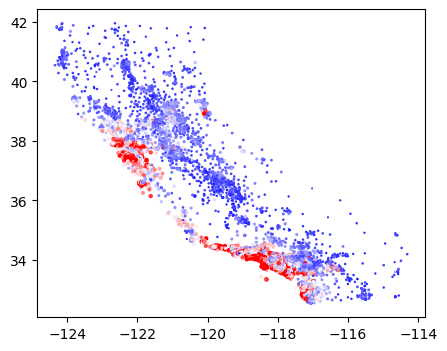

In [15]:
plt.figure(figsize=(5, 4), dpi=100)
plt.scatter(data.Longitude, data.Latitude, s=data.target, c=data.target, cmap='bwr');

(Compare this plot with the map of California: https://en.wikipedia.org/wiki/California)

A kNN model might be quite reasonable to use on this 2D subspace.

Let's first divide our data into train and test:

In [16]:
X, y = data.drop('target', axis=1), data['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1234)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(15480, 8) (5160, 8) (15480,) (5160,)


 - Build a kNN regressor on the `Longitude` and `Latitude` features (**0.5 point**)
 - Build a random forest regressor on the rest of the features (**0.5 point**)
 - Build a stacking regressor (`sklearn.ensemble.StackingRegressor`) with 5-fold cross-val-predict using the two models above as the base models and a linear regression model as the final (aggregating) estimator. Don't forget to optimize hyper-parameters of your models. (**4 points**)
 - Compare the test MSE losses of the 3 models above, leave a comment (**1 point**)


Make sure to have a look at the documentation:
https://scikit-learn.org/stable/modules/ensemble.html#stacking

You can make a pipeline (`sklearn.pipeline.make_pipeline`) with a `ColumnTransformer` (`sklearn.compose.make_column_transformer`) and a regression model (knn or random forest), where the `ColumnTransformer` will select the desired columns from the dataset (see the docs for the column transformer: https://scikit-learn.org/stable/modules/generated/sklearn.compose.make_column_transformer.html).

In [17]:
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error

In [18]:
from sklearn.model_selection import GridSearchCV, KFold

# Selected separate features for the two base models.
location_features = ["Longitude", "Latitude"]
other_features = [column for column in X_train.columns if column not in location_features]

knn = make_pipeline(
    make_column_transformer(("passthrough", location_features)),
    KNeighborsRegressor(),
)
forest = make_pipeline(
    make_column_transformer(("passthrough", other_features)),
    RandomForestRegressor(random_state=42),
)

# Tuned both models on the training data using the same five folds.
cv = KFold(n_splits=5, shuffle=True, random_state=42)
knn_grid = {
    "kneighborsregressor__n_neighbors": [5, 10, 20, 40, 80],
    "kneighborsregressor__weights": ["uniform", "distance"],
    "kneighborsregressor__p": [1, 2],
}
knn_search = GridSearchCV(knn, knn_grid, scoring="neg_mean_squared_error", cv=cv, n_jobs=4)
knn_search.fit(X_train, y_train)
print("Best kNN parameters:", knn_search.best_params_)
print(f"Best kNN CV MSE: {-knn_search.best_score_:.4f}")

forest_grid = {
    "randomforestregressor__n_estimators": [100, 200],
    "randomforestregressor__max_depth": [None, 15],
    "randomforestregressor__min_samples_leaf": [1, 3],
}
forest_search = GridSearchCV(forest, forest_grid, scoring="neg_mean_squared_error", cv=cv, n_jobs=4)
forest_search.fit(X_train, y_train)
print("Best forest parameters:", forest_search.best_params_)
print(f"Best forest CV MSE: {-forest_search.best_score_:.4f}")

best_knn = knn_search.best_estimator_
best_forest = forest_search.best_estimator_

# Trained the final linear model on five-fold out-of-fold predictions.
stacking = StackingRegressor(
    estimators=[("knn", best_knn), ("forest", best_forest)],
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=4,
)
stacking.fit(X_train, y_train)

# Evaluated the three fitted models on the untouched test set.
models = {"kNN": best_knn, "Random forest": best_forest, "Stacking": stacking}
results = []
for name, model in models.items():
    predictions = model.predict(X_test)
    results.append({"Model": name, "Test MSE": mean_squared_error(y_test, predictions)})

comparison = pd.DataFrame(results).set_index("Model")
print("\nTest results:")
print(comparison.round(4).to_string())

Best kNN parameters: {'kneighborsregressor__n_neighbors': 5, 'kneighborsregressor__p': 2, 'kneighborsregressor__weights': 'uniform'}
Best kNN CV MSE: 0.2838
Best forest parameters: {'randomforestregressor__max_depth': 15, 'randomforestregressor__min_samples_leaf': 3, 'randomforestregressor__n_estimators': 200}
Best forest CV MSE: 0.4072

Test results:
               Test MSE
Model                  
kNN              0.2973
Random forest    0.4243
Stacking         0.2319


## Short report

The kNN model used only longitude and latitude, while the random forest used the other six features. I selected their parameters using five-fold cross-validation on the training data. I compared 20 kNN settings and 8 random forest settings, using MSE as the selection metric.

The stacking model combined the two selected models with linear regression. The final model learned from five-fold out-of-fold predictions. The base models were then fitted on the full training set for prediction.

| Model | Test MSE |
|---|---:|
| kNN | 0.2973 |
| Random forest | 0.4243 |
| Stacking | 0.2319 |

The **Stacking** model achieved the lowest test MSE. Combining the location-based predictions with predictions from the other housing features reduced the error compared with either model alone.

I used the test set only for the final comparison. The CV scores were used for parameter selection, so I treated them as tuning results rather than independent quality estimates.